# Experiment 4: Interactive Dashboards with Filters and Slicers

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.DataFrame({
    'Date': pd.to_datetime([
        '2025-01-10', '2025-01-22', '2025-02-05', '2025-02-18', '2025-03-04', '2025-03-21',
        '2025-04-08', '2025-04-19', '2025-05-03', '2025-05-25', '2025-06-11', '2025-06-28'
    ]),
    'Region': ['North', 'South', 'North', 'West', 'East', 'North', 'South', 'West', 'North', 'East', 'South', 'North'],
    'Category': ['Technology', 'Furniture', 'Technology', 'Office Supplies', 'Technology', 'Furniture', 'Technology', 'Furniture', 'Technology', 'Office Supplies', 'Furniture', 'Technology'],
    'Sales': [4500, 3200, 5100, 1800, 4900, 2700, 5600, 3900, 6200, 2100, 4100, 6800],
    'Profit': [1100, 450, 1300, 500, 1250, 300, 1450, 600, 1650, 620, 700, 1800]
})
print(df.head())

        Date Region         Category  Sales  Profit
0 2025-01-10  North       Technology   4500    1100
1 2025-01-22  South        Furniture   3200     450
2 2025-02-05  North       Technology   5100    1300
3 2025-02-18   West  Office Supplies   1800     500
4 2025-03-04   East       Technology   4900    1250


In [3]:
selected_region = 'North'
selected_category = 'Technology'
start_date = '2025-01-01'
end_date = '2025-06-30'

filtered_df = df[
    (df['Region'] == selected_region) &
    (df['Category'] == selected_category) &
    (df['Date'] >= start_date) &
    (df['Date'] <= end_date)
]
print("Filtered KPI - Total Sales:", filtered_df['Sales'].sum())
print("Filtered KPI - Total Profit:", filtered_df['Profit'].sum())
print(filtered_df)

Filtered KPI - Total Sales: 22600
Filtered KPI - Total Profit: 5850
         Date Region    Category  Sales  Profit
0  2025-01-10  North  Technology   4500    1100
2  2025-02-05  North  Technology   5100    1300
8  2025-05-03  North  Technology   6200    1650
11 2025-06-28  North  Technology   6800    1800


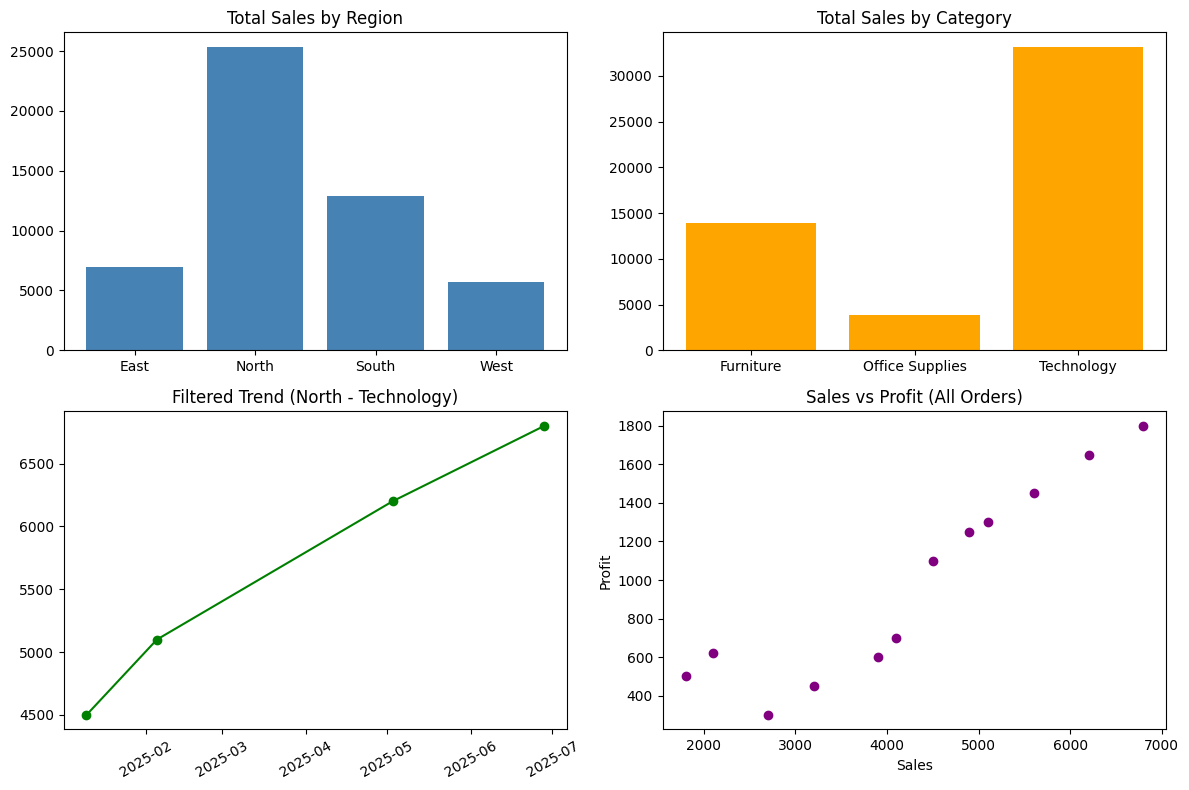

In [4]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
reg_sales = df.groupby('Region')['Sales'].sum()
plt.bar(reg_sales.index, reg_sales.values, color='steelblue')
plt.title('Total Sales by Region')

plt.subplot(2, 2, 2)
cat_sales = df.groupby('Category')['Sales'].sum()
plt.bar(cat_sales.index, cat_sales.values, color='orange')
plt.title('Total Sales by Category')

plt.subplot(2, 2, 3)
plt.plot(filtered_df['Date'], filtered_df['Sales'], marker='o', color='green')
plt.title('Filtered Trend (' + selected_region + ' - ' + selected_category + ')')
plt.xticks(rotation=30)

plt.subplot(2, 2, 4)
plt.scatter(df['Sales'], df['Profit'], color='purple')
plt.title('Sales vs Profit (All Orders)')
plt.xlabel('Sales')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()